# Лабораторная работа №1: метод обратного распространения ошибки

In [1]:
import gzip
import struct
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

SEED = 42
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.3.4


In [2]:
DATA_DIR = Path("mnist_data")
DATA_DIR.mkdir(exist_ok=True)

def download(url, path):
    if not path.exists():
        print("Скачивание:", url)
        urllib.request.urlretrieve(url, path)

def read_idx_images(path):
    with gzip.open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        assert magic == 2051
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def read_idx_labels(path):
    with gzip.open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        assert magic == 2049
        return np.frombuffer(f.read(), dtype=np.uint8)

base = "https://storage.googleapis.com/cvdf-datasets/mnist/"
files = {
    "x_train": "train-images-idx3-ubyte.gz",
    "y_train": "train-labels-idx1-ubyte.gz",
    "x_test": "t10k-images-idx3-ubyte.gz",
    "y_test": "t10k-labels-idx1-ubyte.gz",
}
for filename in files.values():
    download(base + filename, DATA_DIR / filename)

x_train_images = read_idx_images(DATA_DIR / files["x_train"])
y_train = read_idx_labels(DATA_DIR / files["y_train"])
x_test_images = read_idx_images(DATA_DIR / files["x_test"])
y_test = read_idx_labels(DATA_DIR / files["y_test"])

x_train = x_train_images.reshape(len(x_train_images), -1).astype(np.float32) / 255.0
x_test = x_test_images.reshape(len(x_test_images), -1).astype(np.float32) / 255.0

print(f"Тренировочная выборка: X={x_train.shape}, y={y_train.shape}")
print(f"Тестовая выборка:      X={x_test.shape}, y={y_test.shape}")
print(f"Одно изображение: {x_train_images[0].shape}, одна метка: скаляр {y_train[0].shape}")
print(f"Диапазон признаков после нормировки: [{x_train.min():.1f}, {x_train.max():.1f}]")


Тренировочная выборка: X=(60000, 784), y=(60000,)
Тестовая выборка:      X=(10000, 784), y=(10000,)
Одно изображение: (28, 28), одна метка: скаляр ()
Диапазон признаков после нормировки: [0.0, 1.0]


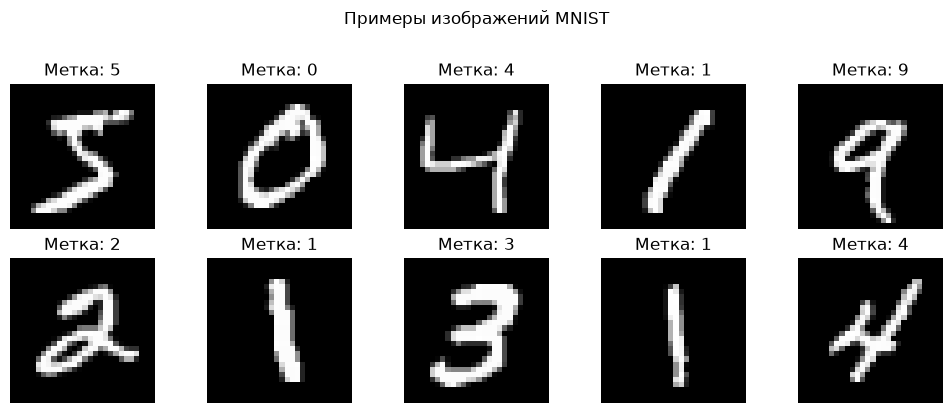

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), x_train_images[:10], y_train[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Метка: {label}")
    ax.axis("off")
fig.suptitle("Примеры изображений MNIST", y=1.02)
plt.tight_layout()
plt.show()


In [4]:
class TwoLayerNetwork:
    def __init__(self, input_size=784, hidden_size=300, output_size=10, seed=42):
        generator = np.random.default_rng(seed)
        self.W1 = (generator.standard_normal((input_size, hidden_size))
                   * np.sqrt(2.0 / input_size)).astype(np.float32)
        self.b1 = np.zeros((1, hidden_size), dtype=np.float32)
        self.W2 = (generator.standard_normal((hidden_size, output_size))
                   * np.sqrt(2.0 / hidden_size)).astype(np.float32)
        self.b2 = np.zeros((1, output_size), dtype=np.float32)

    @staticmethod
    def softmax(logits):
        shifted = logits - logits.max(axis=1, keepdims=True)
        exp_values = np.exp(shifted)
        return exp_values / exp_values.sum(axis=1, keepdims=True)

    @staticmethod
    def cross_entropy(probabilities, targets):
        return float(-np.sum(targets * np.log(np.clip(probabilities, 1e-12, 1.0)))
                     / len(targets))

    def forward(self, X):
        z1 = X @ self.W1 + self.b1
        a1 = np.maximum(z1, 0.0)
        probabilities = self.softmax(a1 @ self.W2 + self.b2)
        return probabilities, (X, z1, a1, probabilities)

    def backward(self, cache, targets):
        X, z1, a1, probabilities = cache
        batch_size = X.shape[0]
        dz2 = (probabilities - targets) / batch_size
        dW2 = a1.T @ dz2
        db2 = dz2.sum(axis=0, keepdims=True)
        dz1 = (dz2 @ self.W2.T) * (z1 > 0.0)
        dW1 = X.T @ dz1
        db1 = dz1.sum(axis=0, keepdims=True)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    def step(self, gradients, learning_rate):
        self.W1 -= learning_rate * gradients["W1"]
        self.b1 -= learning_rate * gradients["b1"]
        self.W2 -= learning_rate * gradients["W2"]
        self.b2 -= learning_rate * gradients["b2"]

    def predict(self, X, batch_size=64):
        predictions = []
        for start in range(0, len(X), batch_size):
            probabilities, _ = self.forward(X[start:start + batch_size])
            predictions.append(probabilities.argmax(axis=1))
        return np.concatenate(predictions)

    def accuracy(self, X, y):
        return float(np.mean(self.predict(X) == y))


In [5]:
HIDDEN_SIZE = 300
LEARNING_RATE = 0.1
BATCH_SIZE = 64
EPOCHS = 20

model = TwoLayerNetwork(x_train.shape[1], HIDDEN_SIZE, 10, seed=SEED)
targets = np.eye(10, dtype=np.float32)[y_train]
history = {"loss": [], "train_accuracy": [], "epoch_time": []}
train_rng = np.random.default_rng(SEED)

training_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    order = train_rng.permutation(len(x_train))
    total_loss = 0.0
    examples_seen = 0

    for start in range(0, len(order), BATCH_SIZE):
        batch_indices = order[start:start + BATCH_SIZE]
        X_batch = x_train[batch_indices]
        y_batch = targets[batch_indices]

        probabilities, cache = model.forward(X_batch)
        batch_loss = model.cross_entropy(probabilities, y_batch)
        gradients = model.backward(cache, y_batch)
        model.step(gradients, LEARNING_RATE)

        total_loss += batch_loss * len(X_batch)
        examples_seen += len(X_batch)

    epoch_loss = total_loss / examples_seen
    train_accuracy = model.accuracy(x_train, y_train)
    elapsed = time.perf_counter() - epoch_start
    history["loss"].append(epoch_loss)
    history["train_accuracy"].append(train_accuracy)
    history["epoch_time"].append(elapsed)
    print(f"Эпоха {epoch:2d}/{EPOCHS} | loss: {epoch_loss:.4f} | "
          f"ошибка train: {1 - train_accuracy:.2%} | время: {elapsed:.2f} с")

print(f"Общее время обучения: {time.perf_counter() - training_start:.2f} с")


Эпоха  1/20 | loss: 0.3545 | ошибка train: 6.08% | время: 1.12 с


Эпоха  2/20 | loss: 0.1834 | ошибка train: 4.28% | время: 1.19 с


Эпоха  3/20 | loss: 0.1369 | ошибка train: 3.25% | время: 0.99 с


Эпоха  4/20 | loss: 0.1095 | ошибка train: 2.57% | время: 0.96 с


Эпоха  5/20 | loss: 0.0913 | ошибка train: 2.18% | время: 0.99 с


...

Эпоха 16/20 | loss: 0.0259 | ошибка train: 0.45% | время: 0.98 с


Эпоха 17/20 | loss: 0.0235 | ошибка train: 0.32% | время: 0.97 с


Эпоха 18/20 | loss: 0.0215 | ошибка train: 0.34% | время: 1.00 с


Эпоха 19/20 | loss: 0.0199 | ошибка train: 0.39% | время: 1.14 с


Эпоха 20/20 | loss: 0.0183 | ошибка train: 0.23% | время: 1.09 с
Общее время обучения: 21.63 с


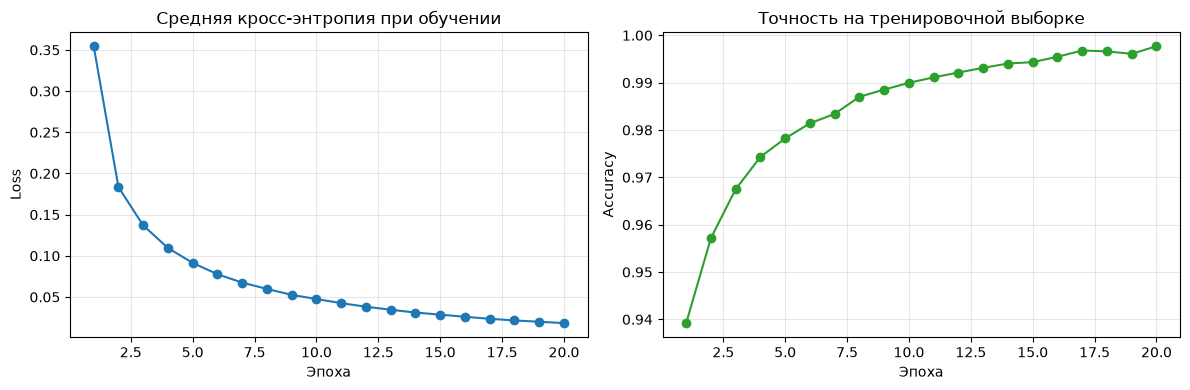

In [6]:
epochs_axis = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_axis, history["loss"], marker="o")
axes[0].set(title="Средняя кросс-энтропия при обучении", xlabel="Эпоха", ylabel="Loss")
axes[0].grid(alpha=0.3)
axes[1].plot(epochs_axis, history["train_accuracy"], marker="o", color="tab:green")
axes[1].set(title="Точность на тренировочной выборке", xlabel="Эпоха", ylabel="Accuracy")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


Точность на тестовой выборке: 98.15%
Ошибка классификации на тестовой выборке: 1.85%


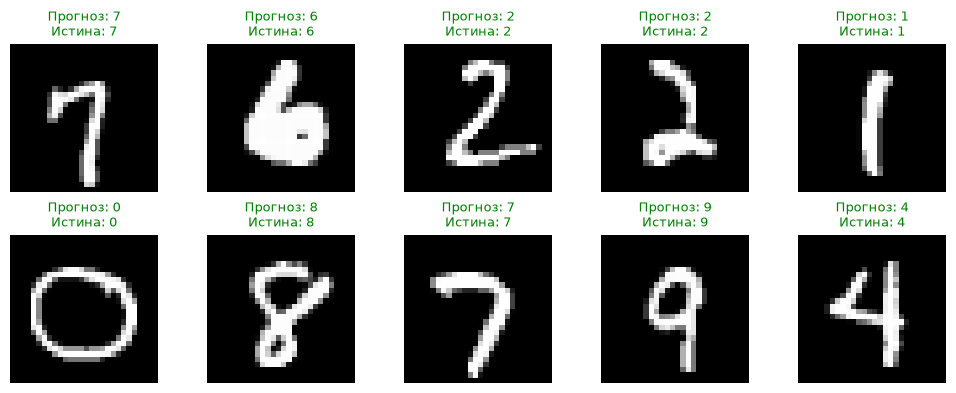

In [7]:
test_predictions = model.predict(x_test)
test_accuracy = np.mean(test_predictions == y_test)
test_error = 1.0 - test_accuracy
print(f"Точность на тестовой выборке: {test_accuracy:.2%}")
print(f"Ошибка классификации на тестовой выборке: {test_error:.2%}")

indices = rng.choice(len(x_test), size=10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, index in zip(axes.ravel(), indices):
    correct = test_predictions[index] == y_test[index]
    ax.imshow(x_test_images[index], cmap="gray")
    ax.set_title(
        f"Прогноз: {test_predictions[index]}\nИстина: {y_test[index]}",
        color="green" if correct else "red",
        fontsize=9,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()
